<a href="https://colab.research.google.com/github/05haileywang/Econ3916_PS5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [118]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from scipy.special import expit
from scipy.optimize import brentq

np.random.seed(42)

n = 10000

# Loan applicant features
income = np.random.normal(65000, 15000, n).clip(15000)
debt_to_income = np.random.uniform(0.05, 0.65, n)
credit_history = np.random.randint(1, 31, n)
prior_delinquencies = np.random.poisson(0.5, n)
loan_amount = np.random.uniform(5000, 50000, n)

# Irrelevant features
random_score = np.random.normal(0, 1, n)
random_number = np.random.uniform(0, 100, n)
random_category = np.random.randint(0, 10, n)

# Combine into DataFrame
X = pd.DataFrame({
    "income": income,
    "debt_to_income": debt_to_income,
    "credit_history": credit_history,
    "prior_delinquencies": prior_delinquencies,
    "loan_amount": loan_amount,
    "random_score": random_score,
    "random_number": random_number,
    "random_category": random_category
})

In [119]:
# Risk score using the relevant features
risk_score = (
    -0.5 * (income / 65000)
    + 2.5 * debt_to_income
    - 0.04 * credit_history
    + 0.6 * prior_delinquencies
    + 0.000015 * loan_amount
)

# Intercept that gives approximately 7% defaults
intercept = brentq(
    lambda a: expit(a + risk_score).mean() - 0.07,
    -20, 20
)

# Default outcomes
probability = expit(intercept + risk_score)
y = pd.Series(np.random.binomial(1, probability), name="default")

In [120]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Test default rate:", round(y_test.mean(), 4))

Training observations: 8000
Test observations: 2000
Test default rate: 0.0695


Step 1.1: I created a dataset with 10,000 loan application and 5 features that can affect the probability of the loan defaulting: income, debt-to-income ratio, credit history length, prior delinquencies, and loan amount. I also included 3 random features that do not affect the probability of a loan defaulting. I wanted to see if the model can correctly identify which features are important to default risk.

The outcome of this test is that 7% of applicants will default on their loan. I split the data into 80% training and 20% testing. I wanted to train the model on a portion of the data and then evaluate the performance against the other data.

In [121]:
from sklearn.metrics import accuracy_score

# Predict no default for everyone
y_null = np.zeros(len(y_test))

# Calculate accuracy
null_accuracy = accuracy_score(y_test, y_null)

print("Null Model Accuracy:", round(null_accuracy, 4))

Null Model Accuracy: 0.9305


Step 1.2: I created a null model that will predict that no applicants will default. The null model had an accuracy of 93.05%, but this is misleading because it did not identify any applicants who defaulted. However, the model failts to identify any applicants that default. I will use this as a baseline accurary to compare the effectivenss of other models.

In [122]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic regression without regularization
log_model = LogisticRegression(penalty=None, max_iter=1000)
log_model.fit(X_train_scaled, y_train)

# Predict defaults on the test set
y_pred_log = log_model.predict(X_test_scaled)

# Calculate accuracy
log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", round(log_accuracy, 4))
print("Null Model Accuracy:", round(null_accuracy, 4))

Logistic Regression Accuracy: 0.9305
Null Model Accuracy: 0.9305


The logistic regression model was accurate 93.05% of the time, which is the same level of accuracy as the default model. The model was not better at prediciting the number of defaulting applicants.

A potential reason for this is that only 6.95% of applicants will default, so the model may be predicitng that no default for most or all applicants. We will have to examine this further.

In [123]:
from sklearn.linear_model import LogisticRegressionCV

# Fit LASSO using ROC AUC for cross-validation
lasso_model = LogisticRegressionCV(
    Cs=10,
    cv=5,
    penalty="l1",
    solver="liblinear",
    scoring="roc_auc",
    max_iter=1000,
    random_state=42
)

lasso_model.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred_lasso = lasso_model.predict(X_test_scaled)

# Calculate accuracy
lasso_accuracy = accuracy_score(y_test, y_pred_lasso)

print("LASSO Accuracy:", round(lasso_accuracy, 4))
print("Best C:", lasso_model.C_[0])
print("Null Model Accuracy:", round(null_accuracy, 4))

LASSO Accuracy: 0.9305
Best C: 0.3593813663804626
Null Model Accuracy: 0.9305


In [124]:
# Create a table of LASSO coefficients
lasso_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso_model.coef_[0]
})

print(lasso_coefficients)

# Identify features reduced to zero
zero_features = lasso_coefficients[
    lasso_coefficients["Coefficient"] == 0
]

print("\nFeatures reduced to zero:")
print(zero_features["Feature"].tolist())

               Feature  Coefficient
0               income    -0.096558
1       debt_to_income     0.508281
2       credit_history    -0.339567
3  prior_delinquencies     0.387622
4          loan_amount     0.191020
5         random_score     0.055423
6        random_number     0.001642
7      random_category    -0.006926

Features reduced to zero:
[]


Step 2.1: I wrote code for a LASSO logistic regression with cross-validation to determine the best penalty strength. I used the ROC AUC because most of the applicants do not default. Measuring accurcacy is not as relevant here.

The model has a c-value of 0.3594 with an accurary of 93.05%, which is the same accurary as the null model. The LASSO model did not reduce any of the features to zero. It keps all 5 relevant features, but it still included the 3 random features that do not have an impact on default risk.

The intention of the LASSO model is to remove the irrelevant feaures, but this one did not remove any of them. LASSO does not always correctly and remove the irrelevant features.

In [125]:
# Fit Ridge regression with cross-validation
ridge_model = LogisticRegressionCV(
    Cs=10,
    cv=5,
    penalty="l2",
    solver="lbfgs",
    scoring="roc_auc",
    max_iter=1000,
    random_state=42
)

ridge_model.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred_ridge = ridge_model.predict(X_test_scaled)

# Calculate accuracy
ridge_accuracy = accuracy_score(y_test, y_pred_ridge)

print("Ridge Accuracy:", round(ridge_accuracy, 4))
print("Best C:", ridge_model.C_[0])
print("LASSO Accuracy:", round(lasso_accuracy, 4))
print("Null Model Accuracy:", round(null_accuracy, 4))

Ridge Accuracy: 0.9305
Best C: 0.046415888336127774
LASSO Accuracy: 0.9305
Null Model Accuracy: 0.9305


I wrote code for a Ridge regression with cross-validation to find the penalty strength. The model produced a c-value of 0.0464 with an accuracy of 93.05%, which is the same as the LASSO and null model.

Ridge handles features differently from LASSO. Ridge will reduce the coeffcients, but not fully to zero. LASSO can reduce coeffcients to zero, and this reasults in features being removed from the model.

I would prefer to use LASSO if I wanted irrelevant features to be fully removed, and for the model to be simpler. Ridge would be better if I wanted to reduce the impact of ireelevant features but not fully remove them. Since both models had the same accurary, I would need to further examine and runs tests to determine which one is better.

In [126]:
from sklearn.ensemble import RandomForestClassifier

# Fit random forest with 500 trees
rf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    bootstrap=True,
    random_state=42
)

rf.fit(X_train, y_train)

# Predict on the test set
y_pred_rf = rf.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest OOB Accuracy:", round(rf.oob_score_, 4))
print("Random Forest OOB Error:", round(1 - rf.oob_score_, 4))
print("Random Forest Test Accuracy:", round(rf_accuracy, 4))
print("Ridge Accuracy:", round(ridge_accuracy, 4))
print("LASSO Accuracy:", round(lasso_accuracy, 4))

Random Forest OOB Accuracy: 0.9304
Random Forest OOB Error: 0.0696
Random Forest Test Accuracy: 0.93
Ridge Accuracy: 0.9305
LASSO Accuracy: 0.9305


I used a random forest model with 500 decision trees to predict default rates. The model had an OOB accuracy of 93.04% and OOB error of 6.96%. The test accuracy was 93.00%, close to the OOB accuracy. Both measure how well the model performs on data that the trees did not use during training. If the numbers were very different, then the model may not have performed as well on the new data.

The random forest did not perform as well as Ridge and LASSO models. Based on accuracy, the random forest was not as good as the simpler models. I would still want to conduct further analysis and compared other performance measures before deciding which model is best.

In [127]:
from sklearn.inspection import permutation_importance

# Calculate MDI importance
mdi = rf.feature_importances_

# Calculate permutation importance on the test set
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

# Create a comparison table
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "MDI": mdi,
    "Permutation": perm.importances_mean
})

# Sort by MDI importance
importance_df = importance_df.sort_values("MDI", ascending=False)

print(importance_df)

               Feature       MDI  Permutation
1       debt_to_income  0.174704     0.074997
4          loan_amount  0.159696    -0.002413
5         random_score  0.154286     0.012270
6        random_number  0.151973     0.002984
0               income  0.150557     0.007763
2       credit_history  0.095475     0.030820
7      random_category  0.071996    -0.003241
3  prior_delinquencies  0.041312     0.052762


I copred the MDI and permutation importance to determine which features were the most useful for the random forest. The two methods gave different ersults. MDI random loan amount, random score, and random number reltively high, but the permutation importance showed that these features had little impact on the model's performance.

The MDI can give higher importance to features that can take on many different values because the trees have more opportuntieis to split the data. Perfmutation importance hleps to measure how much the model's performance changes hwen a feature is shuffles. Based on permuation importance, debt-to-income ratio, history of defaults, and credit history are the most useful features.

However, just because a feature is important for predicting default does not mean the lender can directly change it. For example, debt-to-income ratio is useful for identifying risky applicants, but declining a loan does not automatically lower an applicant's debt. The lender could use this information to evaluate risk or consider a smaller loan amount instead of automatically declining an applicant.

In [128]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Get predicted probabilities from LASSO
y_prob = lasso_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lasso))

print("\nPrecision:", round(precision_score(y_test, y_pred_lasso, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_lasso), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_lasso), 4))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR AUC (Average Precision):", round(average_precision_score(y_test, y_prob), 4))

Confusion Matrix:
[[1861    0]
 [ 139    0]]

Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC AUC: 0.7071
PR AUC (Average Precision): 0.1833


The LASSO model had an accuracy of 93.05%, but the confusion matrix shows that it predicted no default for every applicant. It missed 139 applicants who actually defaults. The precision, recall, and F1 scores are all zero.

The ROC AUC is 0.7071, meaning that the model can tell apart applicants who are more likely to default than those who are less likely to default. The PR AUC was 0.1833, meaning that predicting defaults is still not that easy for the model to handle.

The precision recall curve is the most useful metric to consider in this case because 6.95% applicants will defualt. the ROC AUC can make the model look better than it acutally is at predicting defaults. The model is unable to indetify defaults at the 0.5 threshold, so we should try evaluating using diffrent thresholds.

Best Threshold: 0.144
Minimum Total Cost: $ 2051681.34
Threshold Difference from 0.5: 0.356


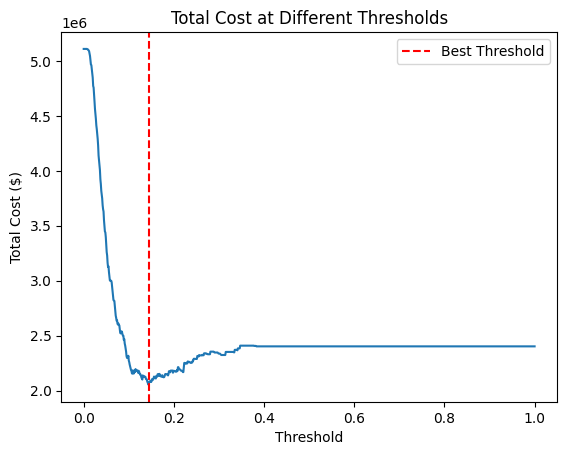

In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define costs
fn_cost = 0.60
fp_cost = 0.10

# Test thresholds from 0 to 1
thresholds = np.linspace(0, 1, 1001)
costs = []

# Calculate the cost at each threshold
for t in thresholds:
    predictions = (y_prob >= t).astype(int)

    false_negatives = (y_test.to_numpy() == 1) & (predictions == 0)
    false_positives = (y_test.to_numpy() == 0) & (predictions == 1)

    cost = (
        (loan_amount[X_test.index][false_negatives] * fn_cost).sum()
        + (loan_amount[X_test.index][false_positives] * fp_cost).sum()
    )

    costs.append(cost)

# Find the threshold with the lowest cost
best_index = np.argmin(costs)
best_threshold = thresholds[best_index]

print("Best Threshold:", round(best_threshold, 3))
print("Minimum Total Cost: $", round(costs[best_index], 2))
print("Threshold Difference from 0.5:", round(0.5 - best_threshold, 3))

# Plot the cost curve
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="red", linestyle="--", label="Best Threshold")
plt.xlabel("Threshold")
plt.ylabel("Total Cost ($)")
plt.title("Total Cost at Different Thresholds")
plt.legend()
plt.show()

The code calcutes the total cost of making incorrect prediction at differetn thresholds. I assumed that the lender loses 50% of the loan amout when an applcnt defaults. For declining a good applicant, I assumed a cost of 10%, which includes an 8% lost interest margin and a 2% reputational cost. I used 2% as an estimate for the potential loss of future business and customer relationships.

The best threshold was 0.144, which is lower than the defautl thewshold of 0.5. At this threshold, the total cost was approximately 2.05 million dollars. This outcome is intuitive because missing an applicant who defaults it more costly than declining a good applicant. If the lower the threwshold, the lender is able to identify more risky applicants, even if they deline some good applicants in the process.

In [130]:
from sklearn.metrics import confusion_matrix

# Predictions at the default threshold
pred_default = (y_prob >= 0.5).astype(int)

# Predictions at the best threshold
pred_best = (y_prob >= best_threshold).astype(int)

print("Confusion Matrix at 0.5:")
print(confusion_matrix(y_test, pred_default))

print("\nConfusion Matrix at Best Threshold:")
print(confusion_matrix(y_test, pred_best))

# Compare costs
default_index = np.argmin(abs(thresholds - 0.5))

print("\nCost at 0.5: $", round(costs[default_index], 2))
print("Cost at Best Threshold: $", round(costs[best_index], 2))
print("Total Savings: $", round(costs[default_index] - costs[best_index], 2))


Confusion Matrix at 0.5:
[[1861    0]
 [ 139    0]]

Confusion Matrix at Best Threshold:
[[1725  136]
 [  96   43]]

Cost at 0.5: $ 2402597.42
Cost at Best Threshold: $ 2051681.34
Total Savings: $ 350916.09


I compared the confusion matrices at the original threshold of 0.5 and the new threshold of 0.144. At 0.5, the model was unable to identify the 129 applicants who defaulted. When the threshold was lowered, the model identified 43 of the defaults, but also incorrectly predicted that 136 applicants will default.

The total cost decreased from 2.40 million dollars to 2.05 million dollars, which means that there is around 15% savings. Loweder the threshold can hlep to save money, even if the incorrectly decline some good applicants. The saving are based on the test data which may not be fully representative of future applicants.

In [131]:
# Test different costs for missing a default
fn_costs = [0.30, 0.60, 0.90]
fp_cost = 0.10

results = []

for fn_cost in fn_costs:
    total_costs = []

    for t in thresholds:
        predictions = (y_prob >= t).astype(int)

        fn = (y_test.to_numpy() == 1) & (predictions == 0)
        fp = (y_test.to_numpy() == 0) & (predictions == 1)

        cost = (
            (X_test["loan_amount"].to_numpy()[fn] * fn_cost).sum()
            + (X_test["loan_amount"].to_numpy()[fp] * fp_cost).sum()
        )

        total_costs.append(cost)

    best = np.argmin(total_costs)

    results.append({
        "FN Cost": fn_cost,
        "FP Cost": fp_cost,
        "Cost Ratio": fn_cost / fp_cost,
        "Best Threshold": thresholds[best],
        "Minimum Cost": total_costs[best]
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

   FN Cost  FP Cost  Cost Ratio  Best Threshold  Minimum Cost
0      0.3      0.1         3.0           0.220   1138376.835
1      0.6      0.1         6.0           0.144   2051681.335
2      0.9      0.1         9.0           0.107   2781699.832


I tested how changing the cost of missing a default would affect the best threshold. I kept the false-positive cost at 10% and changed the false-negative cost from 30% to 60% to 90%.

When the false-negative cost was 30%, the best threshold was 0.220. When it increased to 60%, the threshold decreased to 0.144. At 90%, the best threshold decreased further to 0.107.

As defaults become more expensive, the lender should use a lower threshold to identify more risky applicants. If the cost of missing a default is lower, the lender can use a higher threshold to avoid declining too many good applicants.

I would recommend that the lender adjust the threshold based on the cost of making each type of mistake instead of automatically using 0.5.

AI Expansion for All of Part 4:

Model: ChatGPT (GPT-6)

Date: November 24, 2026

Link to the unedited prompts and responses for all part of section 4: https://chatgpt.com/share/6b063a5e-1630-83e9-bb98-484ac4699fe6

In [132]:
# Import the required libraries
import numpy as np
from scipy.stats import binomtest

# Identify correct predictions for the random forest
rf_correct = np.asarray(y_pred_rf) == np.asarray(y_test)

# Identify correct predictions for the logistic model
logistic_correct = np.asarray(y_pred_lasso) == np.asarray(y_test)

# Count observations where only the random forest is correct
b = np.sum(rf_correct & ~logistic_correct)

# Count observations where only the logistic model is correct
c = np.sum(~rf_correct & logistic_correct)

# Calculate the one-sided exact McNemar p-value
p_value = binomtest(b, b + c, p=0.5, alternative="greater").pvalue if b + c > 0 else 1.0

# Display the accuracy of each model
print("Random forest accuracy:", np.mean(rf_correct))
print("Logistic model accuracy:", np.mean(logistic_correct))

# Display the difference in accuracy
print("Accuracy difference:", np.mean(rf_correct) - np.mean(logistic_correct))

# Display the number of disagreements
print("Only random forest correct:", b)
print("Only logistic model correct:", c)

# Display the p-value
print("P-value:", p_value)

# Determine whether the difference is statistically significant
if p_value < 0.05:
    print("The random forest is significantly more accurate.")
else:
    print("Insufficient evidence that the random forest is more accurate.")

Random forest accuracy: 0.93
Logistic model accuracy: 0.9305
Accuracy difference: -0.0004999999999999449
Only random forest correct: 0
Only logistic model correct: 1
P-value: 1.0
Insufficient evidence that the random forest is more accurate.


Revised AI prompt

[Prep] Continue acting as a model risk analyst comparing two credit models before one goes into production.

[Request] Your previous code correctly used McNemar's test, but I want to make a few changes to better evaluate the models.

[Iterate] Please revise your original Python code with the following changes:

1. Use my existing variables `y_test`, `y_pred_rf`, and `y_pred_lasso`. Do not create any new data or train new models.
2. Calculate `b` (random forest correct, LASSO wrong), `c` (random forest wrong, LASSO correct), and `b + c`.
3. Use the exact binomial test when `b + c` is small (less than 25) and the continuity-corrected McNemar chi-square test otherwise.
4. Use a consistent two-sided test to determine whether the models have significantly different accuracy.
5. Report the p-value, which test was used, and whether the difference is statistically significant at the 5% level.

[Mechanism Check] Explain why McNemar's test is appropriate when both models make predictions on the same test observations. Also explain why an independent-samples test would not be appropriate.

[Evaluate] Explain whether the random forest performs significantly better than LASSO. Also briefly explain why comparing accuracy alone may not be the best approach for a credit risk model where only about 7% of applicants default.

Keep the Python code simple, use only numpy and scipy, and comment each step. Do not assume the result before calculating the p-value.

In [133]:
# Import the required libraries
import numpy as np
from scipy.stats import binomtest, chi2

# Identify correct predictions for each model
rf_correct = np.asarray(y_pred_rf).ravel() == np.asarray(y_test).ravel()
lasso_correct = np.asarray(y_pred_lasso).ravel() == np.asarray(y_test).ravel()

# Count observations where random forest is correct and LASSO is wrong
b = np.sum(rf_correct & ~lasso_correct)

# Count observations where random forest is wrong and LASSO is correct
c = np.sum(~rf_correct & lasso_correct)

# Calculate the total number of disagreements in correctness
n = b + c

# Calculate the accuracy of each model
rf_accuracy = np.mean(rf_correct)
lasso_accuracy = np.mean(lasso_correct)

# Handle the case where there are no disagreements
if n == 0:
    p_value = 1.0
    test_used = "Exact binomial test (no disagreements)"

# Use the two-sided exact binomial test for fewer than 25 disagreements
elif n < 25:
    p_value = binomtest(b, n, p=0.5, alternative="two-sided").pvalue
    test_used = "Exact binomial test"

# Otherwise, use the continuity-corrected McNemar chi-square test
else:
    statistic = (max(abs(b - c) - 1, 0) ** 2) / n
    p_value = chi2.sf(statistic, df=1)
    test_used = "Continuity-corrected McNemar chi-square test"

# Report the accuracy of each model
print("Random forest accuracy:", rf_accuracy)
print("LASSO accuracy:", lasso_accuracy)

# Report the disagreement counts
print("b:", b)
print("c:", c)
print("b + c:", n)

# Report the test used and the p-value
print("Test used:", test_used)
print("P-value:", p_value)

# Evaluate statistical significance and direction at the 5% level
if p_value < 0.05:
    if rf_accuracy > lasso_accuracy:
        print("Random forest is significantly more accurate than LASSO.")
    else:
        print("LASSO is significantly more accurate than random forest.")
else:
    print("There is no statistically significant difference in accuracy.")

Random forest accuracy: 0.93
LASSO accuracy: 0.9305
b: 0
c: 1
b + c: 1
Test used: Exact binomial test
P-value: 1.0
There is no statistically significant difference in accuracy.


I used McNemar's test to compare the random forest and LASSO models because both models made predictions on the same test data. The predictions are paired, so the test that assumes independent samples would not be appropriate.

The random forest had an accuracy of 93.00%, while LASSO had an accuracy of 93.05%. There was only one observation where the models differed in whether they were correct. The random forest was wrong and LASSO was correct on that observation.

Since there was only one disagreement, I used the exact binomial test. The p-value was 1.0, which is greater than 0.05. This means that there was no statistically significant difference in accuracy between the two models. My earlier conclusion that the random forest did not perform better than LASSO still holds.

One limitation is that McNemar's test only compares accuracy. Since the lender is more concerned about the cost of incorrect predictions, comparing the models' costs or PR-AUC using paired test observations would be more useful.

I made a few changes to the original AI code. First, I changed the prediction variable to match the LASSO model in my notebook. I also changed the code so that it uses the exact binomial test when there are fewer than 25 disagreements and the continuity-corrected chi-square test when there are more. Finally, I used a two-sided test to check whether the models had different accuracy.

Part 4B

In [134]:
# Import the required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

# Convert existing variables into one-dimensional arrays
y_original_eval = np.asarray(y_test).ravel()
p_original_eval = np.asarray(y_prob).ravel()

# Split the data into calibration and evaluation subsets
p_cal, p_eval, y_cal, y_eval = train_test_split(
    p_original_eval,
    y_original_eval,
    test_size=0.5,
    random_state=42,
    stratify=y_original_eval
)

# Convert probabilities into log-odds for sigmoid calibration
def log_odds(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# Fit Platt-style sigmoid calibration using the calibration subset
platt = LogisticRegression()
platt.fit(log_odds(p_cal), y_cal)

# Generate Platt-calibrated probabilities
p_platt = platt.predict_proba(log_odds(p_eval))[:, 1]

# Fit isotonic regression using the calibration subset
isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(p_cal, y_cal)

# Generate isotonic-calibrated probabilities
p_isotonic = isotonic.predict(p_eval)

# Store all three sets of evaluation probabilities
models = {
    "Original": p_eval,
    "Platt scaling": p_platt,
    "Isotonic regression": p_isotonic
}

# Report the default prevalence in the evaluation subset
print("Default prevalence:", np.mean(y_eval))

Default prevalence: 0.069


Original bin counts: [100 100 100 100 100 100 100 100 100 100]
Platt scaling bin counts: [100 100 100 100 100 100 100 100 100 100]
Isotonic regression bin counts: [ 44 140  28  89 193  21 189 118 178]


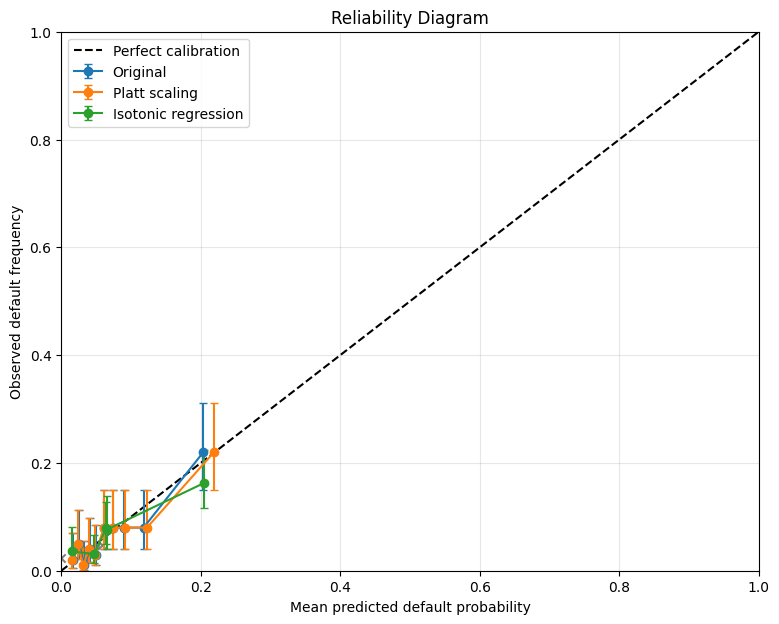

In [135]:
# Create a function to calculate calibration statistics
def calibration_bins(y, p, n_bins=10, min_count=100):

    # Reduce the number of bins when the evaluation sample is small
    n_bins = max(1, min(n_bins, len(y) // min_count))

    # Create quantile-based bin boundaries
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))

    # Assign observations to bins without splitting tied probabilities
    bins = np.digitize(p, edges[1:-1])

    # Create lists to store the results
    predicted, observed, counts = [], [], []

    # Calculate statistics for each non-empty bin
    for i in np.unique(bins):
        mask = bins == i
        predicted.append(np.mean(p[mask]))
        observed.append(np.mean(y[mask]))
        counts.append(np.sum(mask))

    # Return the results as arrays
    return np.array(predicted), np.array(observed), np.array(counts)

# Create the reliability diagram
plt.figure(figsize=(9, 7))

# Plot the perfectly calibrated reference line
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

# Plot the calibration results for each model
for name, probs in models.items():

    # Calculate the bin statistics
    predicted, observed, counts = calibration_bins(y_eval, probs)

    # Calculate approximate 95% Wilson confidence intervals
    z = 1.96
    denominator = 1 + z**2 / counts
    center = (observed + z**2 / (2 * counts)) / denominator
    margin = z * np.sqrt(
        observed * (1 - observed) / counts
        + z**2 / (4 * counts**2)
    ) / denominator

    # Identify bins with sufficient observations
    valid = counts >= 100

    # Plot reliable bins with confidence intervals
    plt.errorbar(
        predicted[valid],
        observed[valid],
        yerr=[
            np.maximum(observed[valid] - (center - margin)[valid], 0),
            np.maximum((center + margin)[valid] - observed[valid], 0)
        ],
        fmt="o-",
        capsize=3,
        label=name
    )

    # Display sparse bins separately using an X marker
    plt.scatter(
        predicted[~valid],
        observed[~valid],
        marker="x",
        color="gray"
    )

    # Report the number of observations in every bin
    print(name, "bin counts:", counts)

# Label the diagram
plt.xlabel("Mean predicted default probability")
plt.ylabel("Observed default frequency")
plt.title("Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

In [136]:
# Create a function to calculate the Brier score decomposition
def brier_decomposition(y, p):

    # Calculate calibration statistics
    predicted, observed, counts = calibration_bins(y, p)

    # Calculate the weight of each bin
    weights = counts / len(y)

    # Calculate the overall default prevalence
    prevalence = np.mean(y)

    # Calculate reliability
    reliability = np.sum(weights * (predicted - observed)**2)

    # Calculate resolution
    resolution = np.sum(weights * (observed - prevalence)**2)

    # Calculate uncertainty
    uncertainty = prevalence * (1 - prevalence)

    # Calculate the original Brier score
    brier = brier_score_loss(y, p)

    # Calculate the grouped Brier score
    grouped_brier = reliability - resolution + uncertainty

    # Calculate the difference caused by grouping probabilities
    residual = brier - grouped_brier

    # Return all results
    return brier, reliability, resolution, uncertainty, residual


# Calculate and report results for all three models
for name, probs in models.items():

    # Calculate the Brier score and decomposition
    brier, rel, res, unc, residual = brier_decomposition(y_eval, probs)

    # Display the results
    print("\nModel:", name)
    print("Brier score:", round(brier, 6))
    print("Reliability:", round(rel, 6))
    print("Resolution:", round(res, 6))
    print("Uncertainty:", round(unc, 6))
    print("Binning residual:", round(residual, 6))
    print("ROC-AUC:", round(roc_auc_score(y_eval, probs), 6))

# Calculate the Brier score of a constant-prevalence prediction
baseline = np.full(len(y_eval), np.mean(y_cal))
print("\nBaseline Brier score:", brier_score_loss(y_eval, baseline))


Model: Original
Brier score: 0.06075
Reliability: 0.000375
Resolution: 0.003189
Uncertainty: 0.064239
Binning residual: -0.000675
ROC-AUC: 0.702315

Model: Platt scaling
Brier score: 0.060728
Reliability: 0.000391
Resolution: 0.003189
Uncertainty: 0.064239
Binning residual: -0.000713
ROC-AUC: 0.702315

Model: Isotonic regression
Brier score: 0.061552
Reliability: 0.00052
Resolution: 0.002357
Uncertainty: 0.064239
Binning residual: -0.000851
ROC-AUC: 0.698026

Baseline Brier score: 0.06423999999999998


In [137]:
# Calculate the original model's performance
original_brier, original_rel, _, _, _ = brier_decomposition(
    y_eval, p_eval
)

# Compare each calibration method with the original model
for name in ["Platt scaling", "Isotonic regression"]:

    # Calculate the calibrated model's performance
    brier, rel, _, _, _ = brier_decomposition(
        y_eval, models[name]
    )

    # Calculate improvements in Brier score and reliability
    brier_improvement = original_brier - brier
    reliability_improvement = original_rel - rel

    # Display the improvements
    print("\nModel:", name)
    print("Brier improvement:", round(brier_improvement, 6))
    print("Reliability improvement:", round(reliability_improvement, 6))

    # Evaluate overall probability prediction performance
    if brier_improvement > 0:
        print("Overall probability predictions improved.")
    else:
        print("Overall probability predictions did not improve.")

    # Evaluate estimated calibration
    if reliability_improvement > 0:
        print("Estimated calibration improved.")
    else:
        print("Estimated calibration did not improve.")


Model: Platt scaling
Brier improvement: 2.2e-05
Reliability improvement: -1.7e-05
Overall probability predictions improved.
Estimated calibration did not improve.

Model: Isotonic regression
Brier improvement: -0.000802
Reliability improvement: -0.000146
Overall probability predictions did not improve.
Estimated calibration did not improve.


Revised prompt

[Prep] Continue acting as a model risk analyst reviewing a credit scoring model.

[Request] I reviewed your calibration code and noticed a few issues that I want to correct.

[Iterate] Please revise your Python code with these changes:

1. Do not use the test set to fit Platt scaling or isotonic regression. Use training data for calibration and keep the test set for final evaluation.
2. My actual Phase 3 cost-minimising threshold was 0.144, not 0.095. Use 0.144 when discussing whether my threshold is reliable.
3. My model is a fitted LASSO logistic regression called `lasso_model`. My existing variables include `X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`, and `y_prob`.
4. Include a complete reliability diagram, Brier score and its decomposition, and a comparison of the original, Platt-scaled, and isotonic-calibrated probabilities.
5. Handle bins with few observations because only about 7% of applicants default.
6. Explain whether calibration improves the model and whether I should keep or recalculate my threshold of 0.144.

[Mechanism Check] Explain why a model can have a good ROC AUC but still have poorly calibrated probabilities. Also explain why fitting calibration models on the test set would be a problem.

[Evaluate] Give me a simple explanation of what the calibration results mean for my lending decision.

Keep the code simple and suitable for Google Colab. Do not create new data or retrain the original LASSO model.

In [138]:
# Import the required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

# Generate training probabilities using the existing fitted LASSO model
p_train = lasso_model.predict_proba(X_train_scaled)[:, 1]

# Reuse the existing test probabilities
p_test = np.asarray(y_prob).ravel()

# Convert the actual outcomes into arrays
y_train_array = np.asarray(y_train).ravel()
y_test_array = np.asarray(y_test).ravel()

# Set the Phase 3 cost-minimizing threshold
threshold = 0.144

# Report the default prevalence
print("Training prevalence:", np.mean(y_train_array))
print("Test prevalence:", np.mean(y_test_array))
print("Phase 3 threshold:", threshold)

Training prevalence: 0.069375
Test prevalence: 0.0695
Phase 3 threshold: 0.144


In [139]:
# Generate the original LASSO decision scores
train_scores = lasso_model.decision_function(X_train_scaled)
test_scores = lasso_model.decision_function(X_test_scaled)

# Fit Platt scaling using training scores only
platt = LogisticRegression(penalty=None)
platt.fit(train_scores.reshape(-1, 1), y_train_array)

# Generate Platt-calibrated test probabilities
p_platt = platt.predict_proba(test_scores.reshape(-1, 1))[:, 1]

# Fit isotonic regression using training probabilities only
isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(p_train, y_train_array)

# Generate isotonic-calibrated test probabilities
p_isotonic = isotonic.predict(p_test)

# Store the three sets of test probabilities
models = {
    "Original LASSO": p_test,
    "Platt scaling": p_platt,
    "Isotonic regression": p_isotonic
}

In [140]:
# Create a function to calculate calibration bin statistics
def calibration_bins(y, p, n_bins=10, min_count=100):

    # Reduce the number of bins if the sample is small
    n_bins = max(1, min(n_bins, len(y) // min_count))

    # Create quantile-based bin boundaries
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))

    # Assign observations to bins
    bins = np.digitize(p, edges[1:-1])

    # Create lists to store the results
    predicted = []
    observed = []
    counts = []

    # Calculate statistics for each non-empty bin
    for i in np.unique(bins):
        mask = bins == i

        # Calculate the average predicted probability
        predicted.append(np.mean(p[mask]))

        # Calculate the actual default rate
        observed.append(np.mean(y[mask]))

        # Count the observations in the bin
        counts.append(np.sum(mask))

    # Return the results as arrays
    return np.array(predicted), np.array(observed), np.array(counts)

Original LASSO bin counts: [200 200 200 200 200 200 200 200 200 200]
Platt scaling bin counts: [200 200 200 200 200 200 200 200 200 200]
Isotonic regression bin counts: [154  76 297 464 192 319 280 218]


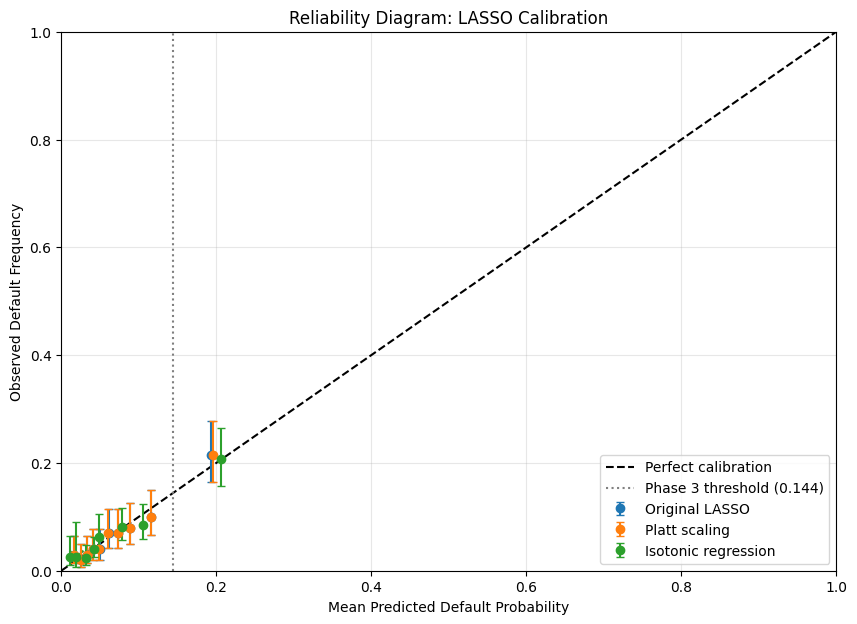

In [141]:
# Create the reliability diagram
plt.figure(figsize=(10, 7))

# Plot the perfectly calibrated reference line
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

# Plot the Phase 3 threshold
plt.axvline(
    threshold, color="gray", linestyle=":",
    label="Phase 3 threshold (0.144)"
)

# Plot each model
for name, probs in models.items():

    # Calculate the calibration statistics
    predicted, observed, counts = calibration_bins(y_test_array, probs)

    # Calculate 95% Wilson confidence intervals
    z = 1.96
    denominator = 1 + z**2 / counts
    center = (observed + z**2 / (2 * counts)) / denominator

    margin = z * np.sqrt(
        observed * (1 - observed) / counts
        + z**2 / (4 * counts**2)
    ) / denominator

    # Calculate the lower and upper error bars
    lower = np.maximum(observed - (center - margin), 0)
    upper = np.maximum((center + margin) - observed, 0)

    # Plot the observed and predicted probabilities
    points = plt.errorbar(
        predicted, observed,
        yerr=[lower, upper],
        fmt="o", capsize=3, label=name
    )

    # Identify bins containing fewer than 100 observations
    sparse = counts < 100

    # Mark sparse bins with an X
    plt.scatter(
        predicted[sparse], observed[sparse],
        marker="x", s=100, color=points[0].get_color()
    )

    # Report the number of observations in each bin
    print(name, "bin counts:", counts)

# Label the diagram
plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Frequency")
plt.title("Reliability Diagram: LASSO Calibration")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [142]:
# Create a function to calculate the Brier score decomposition
def brier_decomposition(y, p):

    # Calculate the calibration bin statistics
    predicted, observed, counts = calibration_bins(y, p)

    # Calculate the weight of each bin
    weights = counts / len(y)

    # Calculate the overall default prevalence
    prevalence = np.mean(y)

    # Calculate reliability
    reliability = np.sum(weights * (predicted - observed)**2)

    # Calculate resolution
    resolution = np.sum(weights * (observed - prevalence)**2)

    # Calculate uncertainty
    uncertainty = prevalence * (1 - prevalence)

    # Calculate the original Brier score
    brier = brier_score_loss(y, p)

    # Calculate the grouped Brier score
    grouped_brier = reliability - resolution + uncertainty

    # Calculate the difference caused by binning
    residual = brier - grouped_brier

    # Return the results
    return brier, reliability, resolution, uncertainty, residual

In [143]:
# Create a dictionary to store the results
results = {}

# Evaluate each model on the test set
for name, probs in models.items():

    # Calculate the Brier score and its decomposition
    brier, rel, res, unc, residual = brier_decomposition(
        y_test_array, probs
    )

    # Calculate ROC AUC
    auc = roc_auc_score(y_test_array, probs)

    # Store the results
    results[name] = {
        "Brier": brier,
        "Reliability": rel,
        "Resolution": res,
        "Uncertainty": unc,
        "Residual": residual,
        "AUC": auc
    }

    # Display the results
    print("\n", name)
    print("Brier score:", round(brier, 6))
    print("Reliability:", round(rel, 6))
    print("Resolution:", round(res, 6))
    print("Uncertainty:", round(unc, 6))
    print("Binning residual:", round(residual, 6))
    print("ROC AUC:", round(auc, 6))

# Calculate the baseline Brier score using training prevalence
baseline = np.full(len(y_test_array), np.mean(y_train_array))

# Report the baseline Brier score
print("\nBaseline Brier score:",
      round(brier_score_loss(y_test_array, baseline), 6))


 Original LASSO
Brier score: 0.061353
Reliability: 0.000119
Resolution: 0.002952
Uncertainty: 0.06467
Binning residual: -0.000483
ROC AUC: 0.70712

 Platt scaling
Brier score: 0.061339
Reliability: 0.000109
Resolution: 0.002952
Uncertainty: 0.06467
Binning residual: -0.000488
ROC AUC: 0.70712

 Isotonic regression
Brier score: 0.06166
Reliability: 0.000105
Resolution: 0.002827
Uncertainty: 0.06467
Binning residual: -0.000287
ROC AUC: 0.703142

Baseline Brier score: 0.06467


In [144]:
# Store the original model's Brier score and reliability
original_brier = results["Original LASSO"]["Brier"]
original_rel = results["Original LASSO"]["Reliability"]

# Compare the calibrated models with the original model
for name in ["Platt scaling", "Isotonic regression"]:

    # Calculate the improvement in Brier score
    brier_improvement = original_brier - results[name]["Brier"]

    # Calculate the improvement in reliability
    rel_improvement = original_rel - results[name]["Reliability"]

    # Display the improvements
    print("\n", name)
    print("Brier improvement:", round(brier_improvement, 6))
    print("Reliability improvement:", round(rel_improvement, 6))

    # Determine whether overall probability predictions improved
    if brier_improvement > 0:
        print("Overall probability predictions improved.")
    else:
        print("Overall probability predictions did not improve.")

    # Determine whether estimated calibration improved
    if rel_improvement > 0:
        print("Estimated calibration improved.")
    else:
        print("Estimated calibration did not improve.")

# Identify the model with the lowest test Brier score
best_model = min(results, key=lambda name: results[name]["Brier"])

# Report the best model based on the Brier score
print("\nLowest Brier score:", best_model)


 Platt scaling
Brier improvement: 1.4e-05
Reliability improvement: 1e-05
Overall probability predictions improved.
Estimated calibration improved.

 Isotonic regression
Brier improvement: -0.000308
Reliability improvement: 1.4e-05
Overall probability predictions did not improve.
Estimated calibration improved.

Lowest Brier score: Platt scaling


In [145]:
# Set a range of 3 percentage points around the threshold
window = 0.03

# Examine each model near the threshold
for name, probs in models.items():

    # Identify applicants close to the threshold
    mask = np.abs(probs - threshold) <= window

    # Count applicants in this probability range
    count = np.sum(mask)

    # Display the model name and sample size
    print("\n", name)
    print("Observations near threshold:", count)

    # Calculate calibration near the threshold
    if count > 0:
        predicted = np.mean(probs[mask])
        observed = np.mean(y_test_array[mask])

        print("Mean predicted probability:", round(predicted, 4))
        print("Observed default rate:", round(observed, 4))
        print("Calibration gap:", round(predicted - observed, 4))
        print("Actual defaults:", np.sum(y_test_array[mask]))

        # Warn about limited observations
        if count < 100 or np.sum(y_test_array[mask]) < 10:
            print("Caution: Limited observations or defaults.")

    else:
        print("No observations near the threshold.")


 Original LASSO
Observations near threshold: 194
Mean predicted probability: 0.1382
Observed default rate: 0.134
Calibration gap: 0.0042
Actual defaults: 26

 Platt scaling
Observations near threshold: 191
Mean predicted probability: 0.1383
Observed default rate: 0.1309
Calibration gap: 0.0074
Actual defaults: 25

 Isotonic regression
Observations near threshold: 230
Mean predicted probability: 0.1501
Observed default rate: 0.1478
Calibration gap: 0.0023
Actual defaults: 34


I used a reliability diagram and the Brier score to check whether the model's predicted probabilities were accurate. The original LASSO model had a Brier score of 0.061353. Platt scaling slightly improved the score to 0.061339, while isotonic regression had a higher score of 0.061660. Since a lower Brier score is better, Platt scaling performed the best, although the improvement was very small.

I also looked at the Brier score decomposition. The reliability values were close to zero for all three models, which suggests that the predicted probabilities were fairly close to the actual default rates. The resolution values showed that the model was able to separate applicants into groups with different levels of risk.

The original model had a ROC AUC of 0.7071, which stayed the same after Platt scaling. This shows that a model can rank applicants correctly without having perfectly accurate probabilities. ROC AUC measures how well the model ranks applicants, while calibration measures whether the predicted probabilities match the actual default rates.

I also checked the probabilities around my original threshold of 0.144. For the original LASSO model, the average predicted probability was 0.1382, compared to an actual default rate of 0.1340. These numbers were fairly close, which suggests that the original probabilities were reasonably calibrated around the threshold.

Overall, Platt scaling slightly improved the Brier score, but the difference was very small. I would not automatically change my threshold of 0.144 based on these results. I would want to test the threshold on separate data before using it for actual lending decisions.

The original AI response used part of the test set to fit the calibration models. I changed this because the test set should be kept for evaluating the models, not fitting them. I also corrected the threshold from 0.095 to my actual threshold of 0.144. Finally, I updated the code to use my existing LASSO model and compared the original, Platt-scaled, and isotonic probabilities.

Recommendation to the Head of Risk

I would not recommend approving the model for production yet. Although the LASSO model had an accuracy of 93.05%, this was the same as the null model that predicted no defaults. At the default threshold of 0.5, the model failed to identify any of the 139 applicants who defaulted.

However, the model still has some value. Its ROC AUC was 0.7071, and its PR AUC was 0.1833, which was higher than the baseline of 0.0695. This suggests that the model can identify differences in default risk, even though its accuracy does not show this.

I found that lowering the threshold to 0.144 reduced the total estimated cost from $2.40 million to $2.05 million, saving approximately $350,916 on the test set. This assumes a 60% loss when an applicant defaults and a 10% cost when a good applicant is declined, including an 8% lost interest margin and a 2% reputational cost.

The calibration results were also fairly good, and Platt scaling slightly improved the Brier score. However, I would want to validate the threshold using separate data before approving the model. If the model continued to reduce costs on new data, I would be more comfortable recommending it for production.